In [1]:
# @title Mounting Google Drive
from google.colab import drive


# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# @title Libraries
from typing import Mapping
import os
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import librosa
import matplotlib.pyplot as plt
from torch import optim
import time
import random
import matplotlib.axes as ax
import pandas as pd
import seaborn as sn
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [3]:
# @title Constants
class_to_int = {
    'neutral' : 0,
    'calm' : 1,
    'happy' : 2,
    'sad': 3,
    'angry': 4,
    'fearful': 5,
    'disgust': 6,
    'surprised': 7
}

int_to_class = {v: k for k, v in class_to_int.items()}

data_pth = '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/combined'
arr_pth = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/RAVDESS'

SAMPLE_RATE = 48000

train_arrs = os.path.join(arr_pth, 'train_arrs')
test_arrs = os.path.join(arr_pth, 'test_arrs')

In [4]:
# @title Datasets
class CombinedDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.audio = sorted(os.listdir(root_dir + '/audio'))
        self.video = sorted(os.listdir(root_dir + '/video'))
        self.label = sorted(os.listdir(root_dir + '/label'))

    def __len__(self):
        return len(os.listdir(self.root_dir + f'/label'))

    def __getitem__(self, idx):
        label = torch.load(self.root_dir + f'/label/{self.label[idx]}')

        start = time.time()
        frames = torch.load(self.root_dir + f'/video/{self.video[idx]}')
        mid = time.time()
        spec = torch.load(self.root_dir + f'/audio/{self.audio[idx]}')
        end = time.time()

        frames = frames.clone().contiguous()
        spec = spec.clone().contiguous()
        label = label.clone() if isinstance(label, torch.Tensor) else torch.tensor(label)

        #print(frames.shape, frames.dtype, frames.numel() * frames.element_size() / 1024**2, "MB")
        #print(f"frames: {mid - start:.3f}s, spec: {end - mid:.3f}s, total: {end - start:.3f}s")
        #print(f"Sample {idx} -> frames: {frames.shape}, spec: {spec.shape}")
        if (frames.shape != (3, 35, 224, 224) or spec.shape != (128, 563)):
            return None
        return frames, spec, label

class AugmentedDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir

        self.audio = sorted(os.listdir(root_dir + '/audio'))
        self.audio_snr_high = sorted(os.listdir(root_dir + '/audio_snr_high'))
        self.audio_snr_low = sorted(os.listdir(root_dir + '/audio_snr_low'))

        self.audio_ls = ['audio', 'audio_snr_high', 'audio_snr_low']
        self.audio_folders = [self.audio, self.audio_snr_high, self.audio_snr_low]

        self.video = sorted(os.listdir(root_dir + '/video'))
        self.label = sorted(os.listdir(root_dir + '/label'))
        self.num_samples = 3

    def __len__(self):
        return len(os.listdir(self.root_dir + '/label')) * self.num_samples

    def __getitem__(self, idx):
        """print(len(self.video))
        print(len(self.label))
        print(len(self.audio_folders[0]))
        print(len(self.audio_folders[1]))
        print(len(self.audio_folders[2]))"""
        base_idx = idx//3
        audio_variant = idx%3
        """print(self.root_dir + f'/label/{self.label[base_idx]}')
        print(self.root_dir + f'/video/{self.video[base_idx]}')
        print(base_idx)
        print(audio_variant)
        print(self.audio_ls[audio_variant])
        print(self.audio_folders[audio_variant])
        print(self.video)
        print(self.label)
        print(self.audio_folders[audio_variant][base_idx])
        """
        #print(self.root_dir + f'/{self.audio_ls[audio_variant]}/{self.audio_folders[audio_variant][base_idx]}')

        label = torch.load(self.root_dir + f'/label/{self.label[base_idx]}')
        start = time.time()


        frames = torch.load(self.root_dir + f'/video/{self.video[base_idx]}')

        mid = time.time()
        spec = torch.load(self.root_dir + f'/{self.audio_ls[audio_variant]}/{self.audio_folders[audio_variant][base_idx]}')
        end = time.time()

        frames = frames.clone().contiguous()
        spec = spec.clone().contiguous()
        label = label.clone() if isinstance(label, torch.Tensor) else torch.tensor(label)

        #print(frames.shape, frames.dtype, frames.numel() * frames.element_size() / 1024**2, "MB")
        #print(f"frames: {mid - start:.3f}s, spec: {end - mid:.3f}s, total: {end - start:.3f}s")
        #print(f"Sample {idx} -> frames: {frames.shape}, spec: {spec.shape}")
        if (frames.shape != (3, 35, 224, 224) or spec.shape != (128, 563)):
            return None
        return frames, spec, label

def safe_collate(batch):
    batch = [x for x in batch if x is not None]  # Drop bad samples
    if len(batch) == 0:
        return None  # or raise
    frames, specs, labels = zip(*batch)

    frames = torch.stack([f.clone() for f in frames])
    specs = torch.stack([s.clone() for s in specs])
    labels = torch.stack([l.clone() if isinstance(l, torch.Tensor) else torch.tensor(l) for l in labels])

    return frames, specs, labels


train_dataset = AugmentedDataset(arr_pth + '/train')
test_dataset = CombinedDataset(arr_pth + '/test')

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=10, collate_fn=safe_collate)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=10, collate_fn=safe_collate)

In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

0

In [5]:
# @title Cross Attention
import torch
import torch.nn as nn
from torchvision import models

import torch
import torch.nn as nn

class AudioNet(nn.Module):
    def __init__(self):
        super().__init__()
        # conv block
        self.conv2Dblock = nn.Sequential(
            # 1. conv block
            nn.Conv2d(in_channels=1,
                       out_channels=16,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.4),
            # 2. conv block
            nn.Conv2d(in_channels=16,
                       out_channels=32,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.4),
            # 3. conv block
            nn.Conv2d(in_channels=32,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.45),
            # 4. conv block
            nn.Conv2d(in_channels=64,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.45)
        )
        # LSTM block
        self.lstm_maxpool = nn.MaxPool2d(kernel_size=[2,4], stride=[2,4])
        self.lstm_maxpool2 = nn.MaxPool1d(kernel_size=4, stride=4)
        hidden_size = 128
        self.lstm = nn.LSTM(input_size=64,hidden_size=hidden_size,bidirectional=True, batch_first=True)
        self.dropout_lstm = nn.Dropout(0.55)
        self.attention_linear = nn.Linear(2*hidden_size,1) # 2*hidden_size for the 2 outputs of bidir LSTM

    def forward(self,x):
        x=x.float()
        # conv embedding
        conv_embedding = self.conv2Dblock(x) #(b,channel,freq,time)
        #print(conv_embedding.shape)
        #print(x.size(0))
        b, c, f, t = conv_embedding.shape
        #print(conv_embedding.shape)
        conv_embedding = conv_embedding.permute(0, 3, 2, 1).reshape(b, t, -1)
        #print(conv_embedding.shape)

        x_reduced = self.lstm_maxpool(x)
        x_reduced = torch.squeeze(x_reduced,1)

        x_reduced = x_reduced.permute(0,2,1)
        lstm_embedding, (h,c) = self.lstm(x_reduced)

        lstm_embedding = lstm_embedding.permute(0,2,1)
        lstm_embedding = self.lstm_maxpool2(lstm_embedding)
        lstm_embedding = lstm_embedding.permute(0,2,1)

        lstm_embedding = self.dropout_lstm(lstm_embedding)

        #print(lstm_embedding.shape)

        attention_embedding = torch.concat([lstm_embedding, conv_embedding], dim=1)
        print(attention_embedding.shape)
        #raise ValueError("Freeze!")

        #output_logits = self.out_linear(complete_embedding)
        #output_logits = self.dropout_linear(output_logits)
        return attention_embedding


class VideoNet(torch.nn.Module):
    def __init__(self):
        super(VideoNet, self).__init__()

        self.conv1 = nn.Conv3d(in_channels=3, out_channels=16, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn1 = nn.BatchNorm3d(16)  # Batch normalization for conv1
        self.conv2 = nn.Conv3d(in_channels=16, out_channels=32, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn2 = nn.BatchNorm3d(32)  # Batch normalization for conv2
        self.conv3 = nn.Conv3d(in_channels=32, out_channels=64, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn3 = nn.BatchNorm3d(64)  # Batch normalization for conv3
        self.conv4 = nn.Conv3d(in_channels=64, out_channels=128, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn4 = nn.BatchNorm3d(128)  # Batch normalization for conv3
        self.conv5 = nn.Conv3d(in_channels=128, out_channels=256, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn5 = nn.BatchNorm3d(256)  # Batch normalization for conv3

        # Max pooling layer
        self.pool1 = nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2))
        self.pool2 = nn.MaxPool3d(kernel_size=(4, 4, 4), stride=(4, 4, 4))
        self.dropout_begin = nn.Dropout3d(p=0.35)
        self.dropout_end = nn.Dropout3d(p=0.4)

    def forward(self, video):
        video = self.pool1(nn.ReLU()(self.bn1(self.conv1(video))))
        video = self.dropout_begin(video)

        #print(video.shape)
        video = self.pool1(nn.ReLU()(self.bn2(self.conv2(video))))

        #print(video.shape)
        video = self.pool1(nn.ReLU()(self.bn3(self.conv3(video))))
        video = self.dropout_end(video)

        #print(video.shape)
        video = self.pool1(nn.ReLU()(self.bn4(self.conv4(video))))

        #print(video.shape)
        video = self.pool1(nn.ReLU()(self.bn5(self.conv5(video))))
        video = self.dropout_end(video)

        #print('video')
        #print(video.shape)
        #print(video.size(0))
        #print("video 3d")
        #print(video.shape)
        #print()
        b, c, d, w, h = video.shape
        video_features = video.reshape(video.size(0), -1, c)
        #print(video_features.shape)
        return video_features

class EmoNet(torch.nn.Module):
    def __init__(self, heads=1, size=256, num_classes=8, num_emotions=8):
        super(EmoNet, self).__init__()
        self.audioNet = AudioNet()
        self.videoNet = VideoNet()
        self.size = size
        self.attn = nn.MultiheadAttention(embed_dim=size, num_heads=heads, batch_first=True)
        self.attn_linear = nn.Linear(256, num_emotions)
        self.attn_dropout = nn.Dropout(p=0.4)


    def forward(self, video, audio):
        video_embedding = self.videoNet(video)
        audio_embedding = self.audioNet(audio)
        #print(1)
        #print(audio_embedding.shape)
        #print(video_embedding.shape)
        attn_scores, _ = self.attn(video_embedding, audio_embedding, audio_embedding)
        #print(attn_scores.shape)
        #print(video_embedding.shape)
        attn_scores = attn_scores.mean(dim=1)
        attn_scores = self.attn_dropout(attn_scores)
        #print(pooled.shape)

        predictions = self.attn_linear(attn_scores)
        return predictions

In [ ]:
# @title Feature Fusion
import torch
import torch.nn as nn
from torchvision import models

import torch
import torch.nn as nn

class AudioNet(nn.Module):
    def __init__(self,num_emotions=100):
        super().__init__()
        # conv block
        self.conv2Dblock = nn.Sequential(
            # 1. conv block
            nn.Conv2d(in_channels=1,
                       out_channels=16,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.35),
            # 2. conv block
            nn.Conv2d(in_channels=16,
                       out_channels=32,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.35),
            # 3. conv block
            nn.Conv2d(in_channels=32,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.4),
            # 4. conv block
            nn.Conv2d(in_channels=64,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.4)
        )
        # LSTM block
        self.lstm_maxpool = nn.MaxPool2d(kernel_size=[2,4], stride=[2,4])
        hidden_size = 128
        self.lstm = nn.LSTM(input_size=64,hidden_size=hidden_size,bidirectional=True, batch_first=True)
        self.dropout_lstm = nn.Dropout(0.1)
        self.attention_linear = nn.Linear(2*hidden_size,1) # 2*hidden_size for the 2 outputs of bidir LSTM
        # Linear softmax layer
        self.out_linear = nn.Linear(2*hidden_size+256,num_emotions)
        self.dropout_linear = nn.Dropout(0.4)
        self.out_softmax = nn.Softmax(dim=1)
    def forward(self,x):
        x=x.float()
        # conv embedding
        conv_embedding = self.conv2Dblock(x) #(b,channel,freq,time)
        conv_embedding = torch.flatten(conv_embedding, start_dim=1) # do not flatten batch dimension
        # lstm embedding
        x_reduced = self.lstm_maxpool(x)
        x_reduced = torch.squeeze(x_reduced,1)
        x_reduced = x_reduced.permute(0,2,1) # (b,t,freq)
        lstm_embedding, (h,c) = self.lstm(x_reduced) # (b, time, hidden_size*2)
        lstm_embedding = self.dropout_lstm(lstm_embedding)
        batch_size,T,_ = lstm_embedding.shape
        attention_weights = [None]*T
        for t in range(T):
            embedding = lstm_embedding[:,t,:]
            attention_weights[t] = self.attention_linear(embedding)
        attention_weights_norm = nn.functional.softmax(torch.stack(attention_weights,-1),-1)
        attention = torch.bmm(attention_weights_norm,lstm_embedding) # (Bx1xT)*(B,T,hidden_size*2)=(B,1,2*hidden_size)
        attention = torch.squeeze(attention, 1)
        # concatenate
        complete_embedding = torch.cat([conv_embedding, attention], dim=1)

        output_logits = self.out_linear(complete_embedding)
        output_logits = self.dropout_linear(output_logits)
        return output_logits


class VideoNet(torch.nn.Module):
    def __init__(self):
        super(VideoNet, self).__init__()

        self.conv1 = nn.Conv3d(in_channels=3, out_channels=16, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn1 = nn.BatchNorm3d(16)  # Batch normalization for conv1
        self.conv2 = nn.Conv3d(in_channels=16, out_channels=32, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn2 = nn.BatchNorm3d(32)  # Batch normalization for conv2
        self.conv3 = nn.Conv3d(in_channels=32, out_channels=64, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn3 = nn.BatchNorm3d(64)  # Batch normalization for conv3
        self.conv4 = nn.Conv3d(in_channels=64, out_channels=128, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn4 = nn.BatchNorm3d(128)  # Batch normalization for conv3
        self.conv5 = nn.Conv3d(in_channels=128, out_channels=256, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn5 = nn.BatchNorm3d(256)  # Batch normalization for conv3

        # Max pooling layer
        self.pool1 = nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2))
        self.pool2 = nn.MaxPool3d(kernel_size=(4, 4, 4), stride=(4, 4, 4))
        self.dropout = nn.Dropout3d(p=0.35)
        self.dropout_linear = nn.Dropout(0.4)
        self.video_fc1 = nn.Sequential(nn.Linear(12544, 100))
    def forward(self, video):
        #print("Input to linear:", video.shape)
        video = self.pool1(nn.ReLU()(self.bn1(self.conv1(video))))
        video = self.dropout(video)

        video = self.pool1(nn.ReLU()(self.bn2(self.conv2(video))))

        video = self.pool1(nn.ReLU()(self.bn3(self.conv3(video))))
        video = self.dropout(video)

        video = self.pool1(nn.ReLU()(self.bn4(self.conv4(video))))

        video = self.pool1(nn.ReLU()(self.bn5(self.conv5(video))))
        video = self.dropout(video)


        video = video.view(video.size(0), -1)
        video_features = self.video_fc1(video)
        video_features = self.dropout(video_features)
        return video_features

class EmoNet(torch.nn.Module):
    def __init__(self, num_emotions=8):
        super(EmoNet, self).__init__()
        self.audioNet = AudioNet()
        self.videoNet = VideoNet()
        self.linear = nn.Linear(200, num_emotions)


    def forward(self, video, audio):
        video_embedding = self.videoNet(video)
        audio_embedding = self.audioNet(audio)
        #print(1)
        #print(audio_embedding.shape)
        #print(video_embedding.shape)
        concat_embedding = torch.cat((video_embedding, audio_embedding), dim=1)

        predictions = self.linear(concat_embedding)
        return predictions

In [ ]:
max_test_acc = 34.7

In [ ]:
# @title Video and Audio Gradient Loading
import gc
torch.cuda.empty_cache()
gc.collect()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet_CrossAttention.pth'

model = EmoNet()
model = model.to(device)
#model.load_state_dict(torch.load(save_path))
num_epochs = 20


In [ ]:
for name, param in model.videoNet.named_parameters():
    if any(layer in name for layer in ['conv1', 'bn1', 'conv2', 'bn2', 'conv3', 'bn3', 'conv4', 'bn4', 'conv5', 'bn5']):
        param.requires_grad = False

for module in model.videoNet.modules():
    if isinstance(module, (nn.BatchNorm3d, nn.BatchNorm2d)):
        module.eval()

In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

24

In [ ]:
max_test_acc=52

In [ ]:
# @title Training
import gc
torch.cuda.empty_cache()
gc.collect()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet_CrossAttention.pth'

model = EmoNet()
model = model.to(device)
model.load_state_dict(torch.load(save_path))
num_epochs = 20

import gc
optimizer = optim.Adam(model.parameters(), lr=0.00001)
criterion = nn.CrossEntropyLoss()

train_acc = []
test_acc = []
#train_acc = [i for i in np.load(arr_pth + '/fc/train_acc.npy')]
#test_acc = [i for i in np.load(arr_pth + '/fc/test_acc.npy')]
#model.load_state_dict(torch.load('/content/drive/MyDrive/COSMOSPosterProject/EmoNet.pth'))
train_loss = []
test_loss = []
#train_loss = [i for i in np.load(arr_pth + '/fc/train_loss.npy')]
#test_loss = [i for i in np.load(arr_pth + '/fc/test_loss.npy')]
print(sum(p.numel() for p in model.parameters()))
for epoch in range(num_epochs):
    torch.cuda.empty_cache()
    gc.collect()
    #print(train_acc)
    #print(test_acc)
    #print(train_loss)
    #print(test_loss)
    model.train()
    epoch_correct = 0
    epoch_total = 0
    running_loss = 0.0
    curr_loss_all = []
    curr_time = time.time()

    x = np.zeros((8, 8))
    curr_num = 0
    for batch in train_dataloader:
        if batch is None:
            continue
        video, audio, labels = batch
        #print(f'labels: {torch.bincount(labels)}')
        video = video.to(device)
        audio = audio.to(device)
        labels = labels.to(device)
        audio = audio.unsqueeze(1)


        # Zero the gradients
        optimizer.zero_grad()
        # Forward pass
        outputs = model(video, audio)
        #print(outputs.shape)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)
        epoch_total += labels.size(0)
        epoch_correct += (predicted == labels).sum().item()

        # Print statistics
        running_loss += loss.item()
        curr_loss_all.append(loss.item())
        if (curr_num % 5 == 4):
            #print(f"Time: {time.time() - curr_time}")
            curr_time = time.time()
            print(f'Epoch {epoch + 1}, Training Batch {curr_num + 1}, Loss: {running_loss / 5:.3f}, Accuracy: {epoch_correct / epoch_total * 100:.2f}%')
            running_loss = 0.0
            #print(epoch_loss)
            #print(epoch_acc)
        del video, audio, labels, batch
        torch.cuda.empty_cache()
        curr_num += 1

    model.eval()
    test_total = 0
    test_correct = 0
    total_loss = 0
    cntr = 1
    with torch.no_grad():
        for batch in test_dataloader:
            if batch is None:
                continue  # skip bad batch
            frames, spec, labels = batch
            frames = frames.to(device)
            spec = spec.to(device)
            labels = labels.to(device)
            spec = spec.unsqueeze(1)
            outputs = model(frames, spec)

            # Accuracy
            _, predicted = torch.max(outputs, 1)
            test_correct += (predicted == labels).sum().item()
            test_total += labels.size(0)

            # Loss
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

            # (Optional) Output logging — softmax predictions
            #probs = F.softmax(outputs, dim=1)
            # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
            cntr += 1

        epoch_loss = total_loss / len(test_dataloader)
        epoch_acc = test_correct / test_total * 100
        print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")
        # Save model after each epoch
        if (epoch_acc > max_test_acc):
            torch.save(model.state_dict(), save_path)
            print(f"Model saved to {save_path}")
            max_test_acc = epoch_acc
        else:
            print("Model Ass, not saved!")

print('Finished Training')

1702537
Epoch 1, Training Batch 5, Loss: 0.881, Accuracy: 65.62%
Epoch 1, Training Batch 10, Loss: 0.845, Accuracy: 68.44%
Epoch 1, Training Batch 15, Loss: 0.740, Accuracy: 69.79%
Epoch 1, Training Batch 20, Loss: 0.980, Accuracy: 68.44%
Epoch 1, Training Batch 25, Loss: 0.771, Accuracy: 69.38%
Epoch 1, Training Batch 30, Loss: 0.790, Accuracy: 68.75%
Epoch 1, Training Batch 35, Loss: 0.716, Accuracy: 69.02%
Epoch 1, Training Batch 40, Loss: 0.710, Accuracy: 69.38%
Epoch 1, Training Batch 45, Loss: 0.663, Accuracy: 69.86%
Epoch 1, Training Batch 50, Loss: 0.908, Accuracy: 69.44%
Epoch 1, Training Batch 55, Loss: 0.831, Accuracy: 69.15%
Epoch 1, Training Batch 60, Loss: 0.947, Accuracy: 68.65%
Epoch 1, Training Batch 65, Loss: 0.811, Accuracy: 68.61%
Epoch 1, Training Batch 70, Loss: 0.766, Accuracy: 68.88%
Epoch 1, Training Batch 75, Loss: 0.775, Accuracy: 69.04%
Epoch 1, Training Batch 80, Loss: 0.693, Accuracy: 69.30%
Epoch 1, Training Batch 85, Loss: 0.906, Accuracy: 69.08%
Epoch 1

NameError: name 'max_test_acc' is not defined

torch.Size([32, 52, 256])
Test Batch 1 Loss: 2.0257 | Accuracy: 53.12%
torch.Size([32, 52, 256])
Test Batch 2 Loss: 0.5469 | Accuracy: 81.25%
torch.Size([32, 52, 256])
Test Batch 3 Loss: 1.8719 | Accuracy: 53.12%
torch.Size([32, 52, 256])
Test Batch 4 Loss: 1.6342 | Accuracy: 65.62%
torch.Size([32, 52, 256])
Test Batch 5 Loss: 0.9425 | Accuracy: 53.12%
torch.Size([32, 52, 256])
Test Batch 6 Loss: 0.6561 | Accuracy: 84.38%
torch.Size([32, 52, 256])
Test Batch 7 Loss: 1.0978 | Accuracy: 43.75%
torch.Size([32, 52, 256])
Test Batch 8 Loss: 0.9750 | Accuracy: 43.75%
torch.Size([32, 52, 256])
Test Batch 9 Loss: 1.4047 | Accuracy: 34.38%
torch.Size([32, 52, 256])
Test Batch 10 Loss: 1.2456 | Accuracy: 37.50%
torch.Size([32, 52, 256])
Test Batch 11 Loss: 0.8585 | Accuracy: 68.75%
torch.Size([32, 52, 256])
Test Batch 12 Loss: 1.0786 | Accuracy: 40.62%
torch.Size([32, 52, 256])
Test Batch 13 Loss: 0.6931 | Accuracy: 78.12%
torch.Size([32, 52, 256])
Test Batch 14 Loss: 1.8781 | Accuracy: 34.38%
t

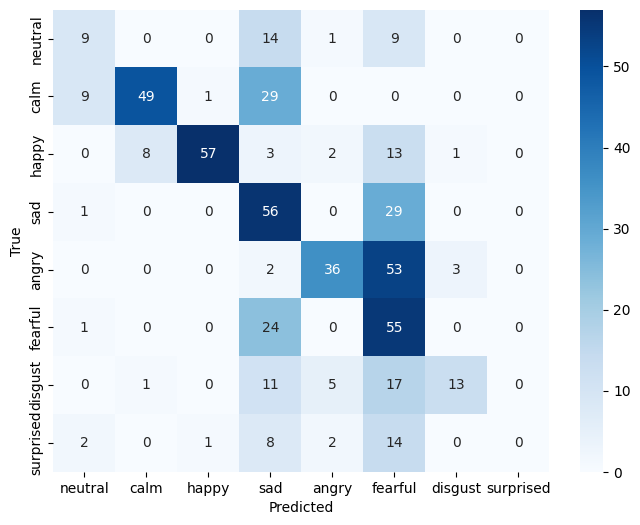

Accuracy: 0.5102040816326531
Precision: 0.6204518799994948
Recall: 0.5102040816326531
F1 Score: 0.5161443110299835


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
# @title CF Generation
import gc
torch.cuda.empty_cache()
gc.collect()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet_CrossAttention.pth'

model = EmoNet()
model = model.to(device)
model.load_state_dict(torch.load(save_path))
num_epochs = 20
correct = 0
total = 0
model.eval()
cntr = 1
criterion = nn.CrossEntropyLoss()
total_loss = 0
preds = []
truths = []
with torch.no_grad():
    for batch in test_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        spec = spec.unsqueeze(1)
        outputs = model(frames, spec)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        preds.append(predicted)
        truths.append(labels)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1


epoch_loss = total_loss / len(test_dataloader)
epoch_acc = correct / total * 100
print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")


preds = torch.cat(preds, dim=0).cpu().numpy()
truths = torch.cat(truths, dim=0).cpu().numpy()
cm = confusion_matrix(truths, preds)
labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.savefig("/content/drive/MyDrive/COSMOSPosterProject/cf_matrix_D.png", dpi=300, bbox_inches='tight')
plt.show()

precision = precision_score(truths, preds, average='weighted')
recall = recall_score(truths, preds, average='weighted')
f1 = f1_score(truths, preds, average='weighted')
accuracy = accuracy_score(truths, preds)

print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')


✅ Saved: combined_cf_2x2.png and .pdf


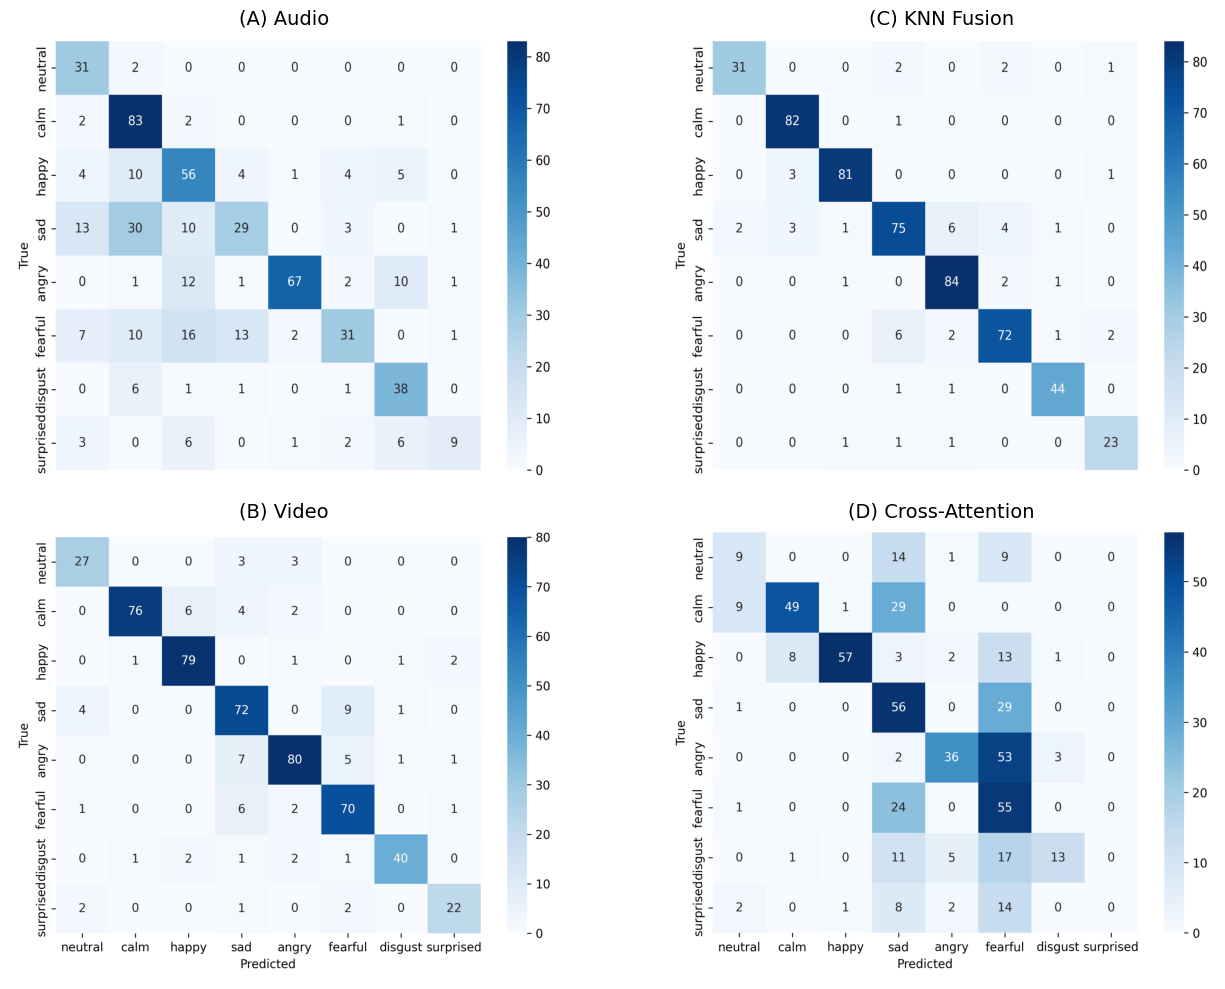

In [15]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import numpy as np
import os

# Base path to your images and save location
pth = '/content/drive/MyDrive/COSMOSPosterProject/'

# Image file names
images = {
    'A': os.path.join(pth, 'cf_matrix_A.png'),
    'B': os.path.join(pth, 'cf_matrix_B.png'),
    'C': os.path.join(pth, 'cf_matrix_C.png'),
    'D': os.path.join(pth, 'cf_matrix_D.png')
}

# Titles for each subplot
titles = {
    'A': '(A) Audio',
    'B': '(B) Video',
    'C': '(C) KNN Fusion',
    'D': '(D) Cross-Attention'
}

# Desired layout
layout = [['A', 'C'],
          ['B', 'D']]

# Load all images and determine the max width & height
resized_images = {}
max_width = 0
max_height = 0

for key, path in images.items():
    with Image.open(path) as img:
        max_width = max(max_width, img.width)
        max_height = max(max_height, img.height)

# Resize all images to the same dimensions
for key, path in images.items():
    with Image.open(path) as img:
        resized = img.resize((max_width, max_height), Image.Resampling.LANCZOS)
        resized_images[key] = np.array(resized)

# Create 2x2 subplot
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Assign each subplot with the resized image
for i in range(2):
    for j in range(2):
        key = layout[i][j]
        ax = axs[i][j]
        ax.imshow(resized_images[key])
        ax.set_title(titles[key], fontsize=14)
        ax.axis('off')

# Save the final figure
plt.tight_layout()
plt.savefig(os.path.join(pth, "combined_cf_2x2.png"), dpi=300)
plt.savefig(os.path.join(pth, "combined_cf_2x2.pdf"), format="pdf")

print("✅ Saved: combined_cf_2x2.png and .pdf")


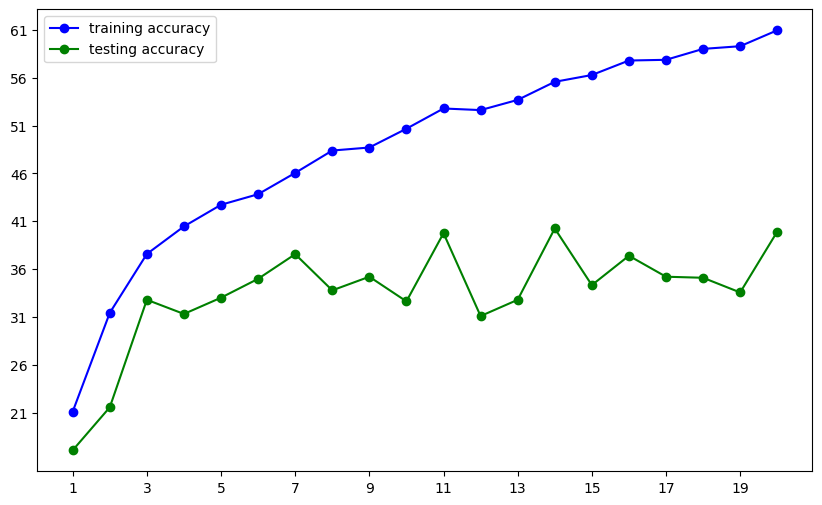

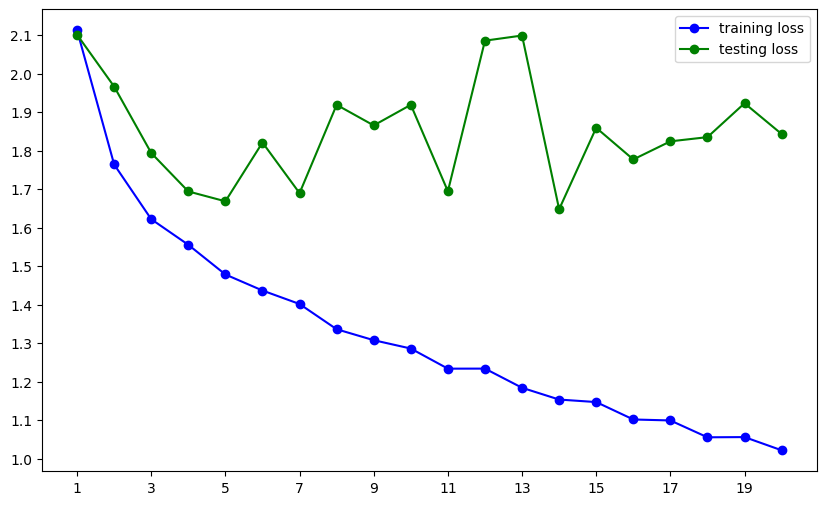

In [ ]:
plt.figure(figsize=(10,6))
train_acc = [i for i in np.load(arr_pth + '/fc/train_acc.npy')]
test_acc = [i for i in np.load(arr_pth + '/fc/test_acc.npy')]
train_loss = [i for i in np.load(arr_pth + '/fc/train_loss.npy')]
test_loss = [i for i in np.load(arr_pth + '/fc/test_loss.npy')]
plt.xticks(np.arange(min(range(1, len(train_acc)+1)), max(range(1, len(train_acc)+1))+2, step=2))
plt.yticks(np.arange(round(min(train_acc)), round(max(train_acc))+2, step=5))
plt.plot(range(1, len(train_acc)+1), train_acc, '-b', marker='o', label='training accuracy')
plt.plot(range(1, len(test_acc)+1), test_acc,  '-g', marker='o', label = 'testing accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.xticks(np.arange(min(range(1, len(train_loss)+1)), max(range(1, len(train_loss)+1))+2, step=2))
plt.yticks(np.arange(round(min(train_loss)), round(max(train_loss))+2, step=0.1))
plt.plot(range(1, len(train_loss)+1), train_loss, '-b', marker='o', label = 'training loss')
plt.plot(range(1, len(test_loss)+1), test_loss,  '-g', marker='o', label = 'testing loss')
plt.legend()
plt.show()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EmoNet()
num_epochs = 20
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
model.load_state_dict(torch.load('/content/drive/MyDrive/COSMOSPosterProject/EmoNet.pth'))
model.to(device)

ls = []
lb = []

with torch.no_grad():
    for batch in os.listdir(test_arrs):
        video, audio, labels = torch.load(os.path.join(test_arrs, batch))
        video = video.to(device)
        audio = audio.to(device)
        labels = labels.to(device)
        audio = audio.unsqueeze(1)
        print(audio.shape)
        outputs = model(video, audio)
        _, predicted = torch.max(outputs.data, 1)
        ls.append(outputs)
        lb.append(labels)
        loss = criterion(outputs, labels)

<ipython-input-21-ac006757b39e>:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/drive/MyDrive/COSMOSPosterProject/EmoNet.pth'))
<

torch.Size([32, 1, 128, 563])
torch.Size([32, 1, 128, 563])
torch.Size([32, 1, 128, 563])


KeyboardInterrupt: 

In [ ]:
ls = torch.totensor(ls)

AttributeError: module 'torch' has no attribute 'totensor'

In [ ]:
import torch
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

def calculate_metrics(logits, labels):
    # Convert logits to probabilities using softmax, then take argmax to get predictions
    predictions = torch.argmax(logits, dim=1)

    # Convert tensors to numpy arrays for metric calculation
    predictions = predictions.cpu().numpy()
    labels = labels.cpu().numpy()

    # Accuracy
    accuracy = accuracy_score(labels, predictions)

    # F1 score
    f1 = f1_score(labels, predictions, average='weighted')

    # Recall
    recall = recall_score(labels, predictions, average='weighted')

    # Precision
    precision = precision_score(labels, predictions, average='weighted')

    return accuracy, f1, recall, precision

# Example usage
logits = torch.tensor([[2.0, 1.0], [1.0, 3.0], [2.0, 2.0]])  # Example logits
labels = torch.tensor([0, 1, 1])  # True labels

accuracy, f1, recall, precision = calculate_metrics(ls, lb)
print(f"Accuracy: {accuracy}")
print(f"F1 Score: {f1}")
print(f"Recall: {recall}")
print(f"Precision: {precision}")